# 1. Predicting Road Accident Risk

## 1.1 Load Data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

DATA_FOLDER = os.path.join("..", "data")
TRAIN_DATA_FILE = os.path.join(DATA_FOLDER, "train.csv")
data = pd.read_csv(TRAIN_DATA_FILE)

## 1.2 Analyze Data

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517754 entries, 0 to 517753
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id                      517754 non-null  int64  
 1   road_type               517754 non-null  object 
 2   num_lanes               517754 non-null  int64  
 3   curvature               517754 non-null  float64
 4   speed_limit             517754 non-null  int64  
 5   lighting                517754 non-null  object 
 6   weather                 517754 non-null  object 
 7   road_signs_present      517754 non-null  bool   
 8   public_road             517754 non-null  bool   
 9   time_of_day             517754 non-null  object 
 10  holiday                 517754 non-null  bool   
 11  school_season           517754 non-null  bool   
 12  num_reported_accidents  517754 non-null  int64  
 13  accident_risk           517754 non-null  float64
dtypes: bool(4), float64(

In [4]:
data.shape

(517754, 14)

In [5]:
data.head()

,id,road_type,num_lanes,curvature,speed_limit,lighting,weather,road_signs_present,public_road,time_of_day,holiday,school_season,num_reported_accidents,accident_risk
0,0,urban,2,0.06,35,daylight,rainy,False,True,afternoon,False,True,1,0.13
1,1,urban,4,0.99,35,daylight,clear,True,False,evening,True,True,0,0.35
2,2,rural,4,0.63,70,dim,clear,False,True,morning,True,False,2,0.30
3,3,highway,4,0.07,35,dim,rainy,True,True,morning,False,False,1,0.21
4,4,rural,1,0.58,60,daylight,foggy,False,False,evening,True,False,1,0.56


In [6]:
data.describe()

,id,num_lanes,curvature,speed_limit,num_reported_accidents,accident_risk
count,517754.000000,517754.000000,517754.000000,517754.000000,517754.000000,517754.000000
mean,258876.500000,2.491511,0.488719,46.112575,1.187970,0.352377
std,149462.849975,1.120434,0.272563,15.788521,0.895961,0.166417
min,0.000000,1.000000,0.000000,25.000000,0.000000,0.000000
25%,129438.250000,1.000000,0.260000,35.000000,1.000000,0.230000
50%,258876.500000,2.000000,0.510000,45.000000,1.000000,0.340000
75%,388314.750000,3.000000,0.710000,60.000000,2.000000,0.460000
max,517753.000000,4.000000,1.000000,70.000000,7.000000,1.000000


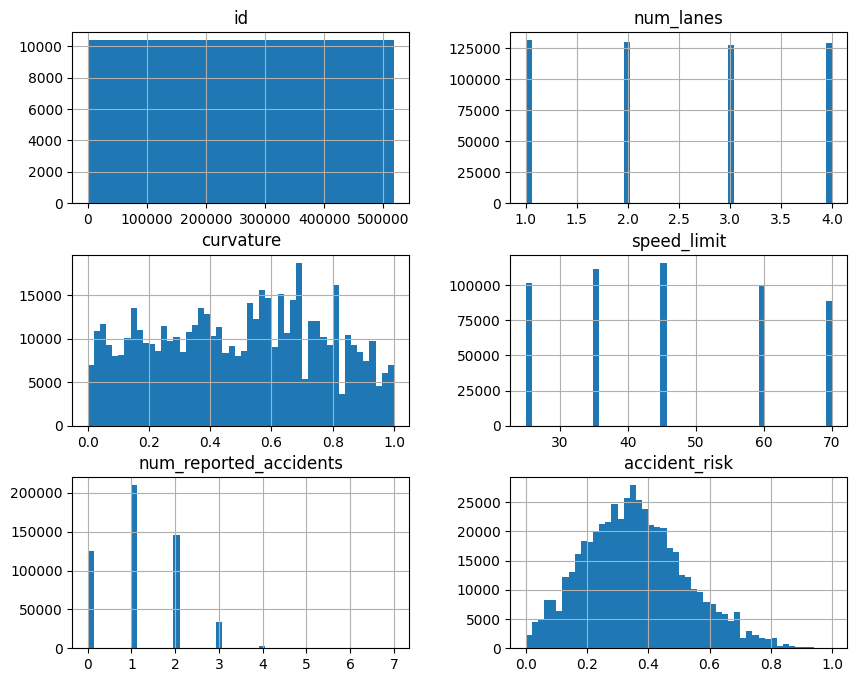

In [7]:
data.hist(bins=50, figsize=(10,8))
plt.show()

In [8]:
data_num = data.drop(columns=['id', 'road_type', 'lighting', 'weather', 'time_of_day'])
data_num.corr()['accident_risk'].sort_values(ascending=False)

accident_risk             1.000000
curvature                 0.543946
speed_limit               0.430898
num_reported_accidents    0.213891
holiday                   0.051129
public_road               0.031032
road_signs_present        0.000629
school_season            -0.000977
num_lanes                -0.006003
Name: accident_risk, dtype: float64

## 1.3 Split test train

In [9]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=['accident_risk', 'id'])
y = data['accident_risk']

X_train, X_val, y_train, y_val = train_test_split(X,y,test_size=0.2, random_state=42)

In [10]:
X_train.shape, X_val.shape, y_train.shape, y_val.shape

((414203, 12), (103551, 12), (414203,), (103551,))

## 1.4 Data Preprocessing

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

num_features = ['num_lanes', 'curvature', 'speed_limit', 'num_reported_accidents']
cat_features = ['road_type', 'lighting', 'weather', 'time_of_day', 'road_signs_present', 'public_road', 'holiday', 'school_season']

num_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])  

cat_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', sparse_output=False))
])  

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ])

In [12]:
preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,copy,True
,with_mean,True
,with_std,True


In [13]:
X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)

In [14]:
X_train.shape, X_val.shape, y_train.shape, y_val.shape

((414203, 16), (103551, 16), (414203,), (103551,))

In [15]:
feature_names = preprocessor.get_feature_names_out()
print(feature_names)

['num__num_lanes' 'num__curvature' 'num__speed_limit'
 'num__num_reported_accidents' 'cat__road_type_rural'
 'cat__road_type_urban' 'cat__lighting_dim' 'cat__lighting_night'
 'cat__weather_foggy' 'cat__weather_rainy' 'cat__time_of_day_evening'
 'cat__time_of_day_morning' 'cat__road_signs_present_True'
 'cat__public_road_True' 'cat__holiday_True' 'cat__school_season_True']


## 1.5 Training

### 1.5.1 LinearRegression

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [16]:
print(lr_model.coef_)
print(lr_model.intercept_)
print(lr_model.rank_)
print(lr_model.singular_)
print(lr_model.n_features_in_)
# print(lr_model.feature_names_in_)


[ 7.28881380e-04  8.85086906e-02  8.05264047e-02  1.41017979e-02
 -7.07925606e-04  1.23423484e-06 -1.70885582e-04  1.87100928e-01
  9.18677388e-02  9.29431961e-02  8.25079009e-04 -1.07799450e-03
 -1.32980749e-03 -6.97310020e-04 -3.99393927e-04  3.40718424e-04]
0.237192279882189
16
[690.69338516 645.82086013 642.61833021 595.02419249 374.56016924
 371.61629557 367.60620152 362.3287295  323.79765291 321.50722464
 321.17752299 318.33132568 219.0459367  214.869777   214.33707086
 210.23289489]
16


In [17]:
y_pred = lr_model.predict(X_val)

mse = mean_squared_error(y_val, y_pred)
rmse = np.sqrt(mse)

print(f"Root Mean Squared Error: {rmse}")

Root Mean Squared Error: 0.07353086258983134


### 1.5.2 DecisionTree

In [18]:
from sklearn.tree import DecisionTreeRegressor

dtr_model = DecisionTreeRegressor(random_state=42)
dtr_model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [19]:
y_pred = dtr_model.predict(X_val)

mse = mean_squared_error(y_val, y_pred)
rmse = np.sqrt(mse)

print(f"Root Mean Squared Error: {rmse}")

score = r2_score(y_val, y_pred)
print("R2 score:", score)

Root Mean Squared Error: 0.08302212606867895
R2 score: 0.7503757451896058


### 1.5.3 RandomForest

In [20]:
from sklearn.ensemble import RandomForestRegressor

rfr_model = RandomForestRegressor(random_state=42, n_jobs=-1)

rfr_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [21]:
y_pred = rfr_model.predict(X_val)

mse = mean_squared_error(y_val, y_pred)
rmse = np.sqrt(mse)

print(f"Root Mean Squared Error: {rmse}")

score = r2_score(y_val, y_pred)
print("R2 score:", score)

Root Mean Squared Error: 0.05966693734204884
R2 score: 0.8710662623305887


### 1.5.4 XGBoost

In [22]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(random_state=42, n_jobs=-1, eval_metric='rmse')
xgb_model.fit(X_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'rmse'


In [23]:
y_pred = xgb_model.predict(X_val)

mse = mean_squared_error(y_val, y_pred)
rmse = np.sqrt(mse)

print(f"Root Mean Squared Error: {rmse}")

score = r2_score(y_val, y_pred)
print("R2 score:", score)

Root Mean Squared Error: 0.0563444243438917
R2 score: 0.8850256475733095


### 1.5.5 Deep Neural Network

In [24]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error
import numpy as np

# ---- ANN Model with BatchNorm ----
model = tf.keras.Sequential([
    layers.Dense(256, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, dtype='float32')
])

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=[tf.keras.metrics.RootMeanSquaredError()]
)

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# ---- Train ----
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=2048,
    callbacks=[early_stop],
    verbose=1
)

2025-11-18 05:24:43.991612: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-11-18 05:24:45.855619: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-11-18 05:24:49.821926: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/rjain/projects/ml/DSAndAIBatch2025/tf_env/lib/python3.10/site-packages/keras/src/laye

Epoch 1/50


2025-11-18 05:24:56.212481: I external/local_xla/xla/service/service.cc:163] XLA service 0x7ddd74004120 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2025-11-18 05:24:56.212544: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 3070 Ti Laptop GPU, Compute Capability 8.6
2025-11-18 05:24:56.308221: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-11-18 05:24:56.717133: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91300
2025-11-18 05:24:56.791660: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2025-11-18 05:24:

 13/203 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1395 - root_mean_squared_error: 0.3616 

I0000 00:00:1763443502.885649    1930 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


200/203 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0274 - root_mean_squared_error: 0.1500

2025-11-18 05:25:05.166266: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2025-11-18 05:25:05.166407: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2025-11-18 05:25:06.494483: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_165', 12 bytes spill stores, 12 bytes spill loads

2025-11-18 05:25:06.801805: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : 

203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0271 - root_mean_squared_error: 0.1493

2025-11-18 05:25:13.566779: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2025-11-18 05:25:14.582583: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_33', 12 bytes spill stores, 12 bytes spill loads

2025-11-18 05:25:14.694561: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_33', 8 bytes spill stores, 8 bytes spill loads

2025-11-18 05:25:14.903068: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_33', 116 bytes spi

203/203 ━━━━━━━━━━━━━━━━━━━━ 21s 64ms/step - loss: 0.0101 - root_mean_squared_error: 0.1002 - val_loss: 0.0044 - val_root_mean_squared_error: 0.0664
Epoch 2/50
203/203 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0039 - root_mean_squared_error: 0.0625 - val_loss: 0.0037 - val_root_mean_squared_error: 0.0607
Epoch 3/50
203/203 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0035 - root_mean_squared_error: 0.0595 - val_loss: 0.0035 - val_root_mean_squared_error: 0.0591
Epoch 4/50
203/203 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0034 - root_mean_squared_error: 0.0585 - val_loss: 0.0034 - val_root_mean_squared_error: 0.0586
Epoch 5/50
203/203 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0034 - root_mean_squared_error: 0.0580 - val_loss: 0.0034 - val_root_mean_squared_error: 0.0584
Epoch 6/50
203/203 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0033 - root_mean_squared_error: 0.0577 - val_loss: 0.0034 - val_root_mean_squared_error: 0.0580
Epoch 7/50
203/203 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss

In [25]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 136,709 (534.02 KB)

 Trainable params: 45,569 (178.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 91,140 (356.02 KB)

In [26]:
loss, rmse = model.evaluate(X_val, y_val)
print(f"Root Mean Squared Error: {rmse}")

score = r2_score(y_val, y_pred)
print("R2 score:", score)

2025-11-18 05:26:06.724708: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2025-11-18 05:26:06.724779: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2025-11-18 05:26:07.379494: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_26', 8 bytes spill stores, 8 bytes spill loads

2025-11-18 05:26:08.272608: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Reg

3235/3236 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0033 - root_mean_squared_error: 0.0572

2025-11-18 05:26:41.807914: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2025-11-18 05:26:41.808030: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2025-11-18 05:26:43.966328: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_33', 292 bytes spill stores, 292 bytes spill loads



3236/3236 ━━━━━━━━━━━━━━━━━━━━ 39s 11ms/step - loss: 0.0033 - root_mean_squared_error: 0.0574
Root Mean Squared Error: 0.057366158813238144
R2 score: 0.8850256475733095


## 1.6 Model Tuning

### 1.6.1 XGBoost

In [16]:
import optuna
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

def objective(trial):

    params = {
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "random_state": 42,
        "n_jobs": -1,
        "tree_method": "hist", 
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.03),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "gamma": trial.suggest_float("gamma", 1e-8, 5.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 5.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 5.0)
    }

    model = XGBRegressor(**params)

    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    preds = model.predict(X_val)
    mse = mean_squared_error(y_val, preds)
    rmse = np.sqrt(mse)

    return rmse 

/home/rjain/projects/ml/DSAndAIBatch2025/tf_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [28]:
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=200)

print("Best RMSE:", study.best_value)
print("Best parameters:", study.best_params)

[I 2025-11-18 05:30:27,158] A new study created in memory with name: no-name-f6268f3d-5e2e-4331-a729-a4e90f2bcea4
[I 2025-11-18 05:31:28,694] Trial 0 finished with value: 0.05649978522749739 and parameters: {'n_estimators': 292, 'max_depth': 9, 'learning_rate': 0.014429432423477554, 'subsample': 0.8902073473672903, 'colsample_bytree': 0.8355566707722846, 'gamma': 2.0745919604950256e-06, 'reg_alpha': 0.05284764186110856, 'reg_lambda': 2.5587214714548208}. Best is trial 0 with value: 0.05649978522749739.
[I 2025-11-18 05:31:55,977] Trial 1 finished with value: 0.05730733687491725 and parameters: {'n_estimators': 406, 'max_depth': 3, 'learning_rate': 0.019724185115981036, 'subsample': 0.8342936784460233, 'colsample_bytree': 0.9384398464575492, 'gamma': 2.2199919535469646e-06, 'reg_alpha': 0.0008000609118852416, 'reg_lambda': 3.2890124847449576}. Best is trial 0 with value: 0.05649978522749739.
[I 2025-11-18 05:32:32,436] Trial 2 finished with value: 0.056387113171285724 and parameters: {'

Best RMSE: 0.056174700226868796
Best parameters: {'n_estimators': 349, 'max_depth': 8, 'learning_rate': 0.021151550484754356, 'subsample': 0.7565248446301757, 'colsample_bytree': 0.9803209278887719, 'gamma': 0.0052179615585946125, 'reg_alpha': 7.304034717889857e-06, 'reg_lambda': 2.4437876646687458}


In [18]:
from sklearn.metrics import r2_score

best_params = {
    "objective": "reg:squarederror",
    "eval_metric": "rmse",
    "random_state": 42,
    "n_jobs": -1,
    "tree_method": "hist",
    "n_estimators": 349, 
    "max_depth": 8, 
    "learning_rate": 0.021151550484754356, 
    "subsample": 0.7565248446301757, 
    "colsample_bytree": 0.9803209278887719, 
    "gamma": 0.0052179615585946125, 
    "reg_alpha": 7.304034717889857e-06, 
    "reg_lambda": 2.4437876646687458
}

from xgboost import XGBRegressor

final_model = XGBRegressor(**best_params)
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_val)

mse = mean_squared_error(y_val, y_pred)
rmse = np.sqrt(mse)

print(f"Root Mean Squared Error: {rmse}")

score = r2_score(y_val, y_pred)
print("R2 score:", score)

Root Mean Squared Error: 0.056174700226868796
R2 score: 0.8857172698646423


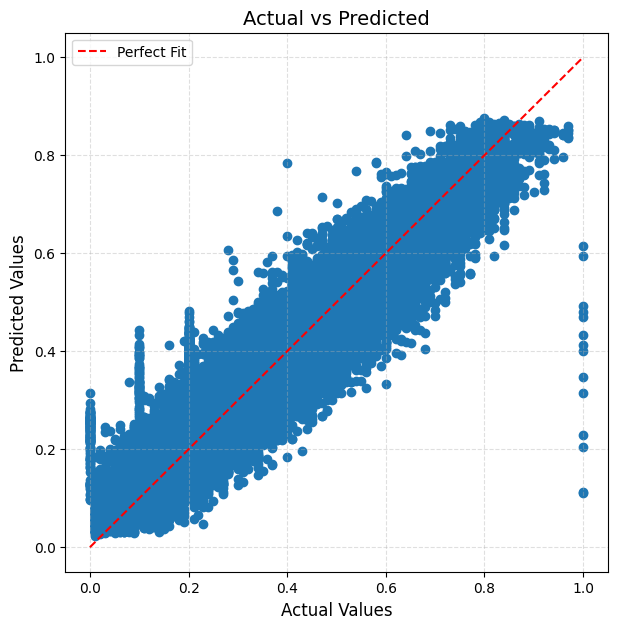

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,7))
plt.scatter(y_val, y_pred)

plt.xlabel("Actual Values", fontsize=12)
plt.ylabel("Predicted Values", fontsize=12)
plt.title("Actual vs Predicted", fontsize=14)

# Perfect prediction line
plt.plot([y_val.min(), y_val.max()],
         [y_val.min(), y_val.max()],
         'r--', label="Perfect Fit")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

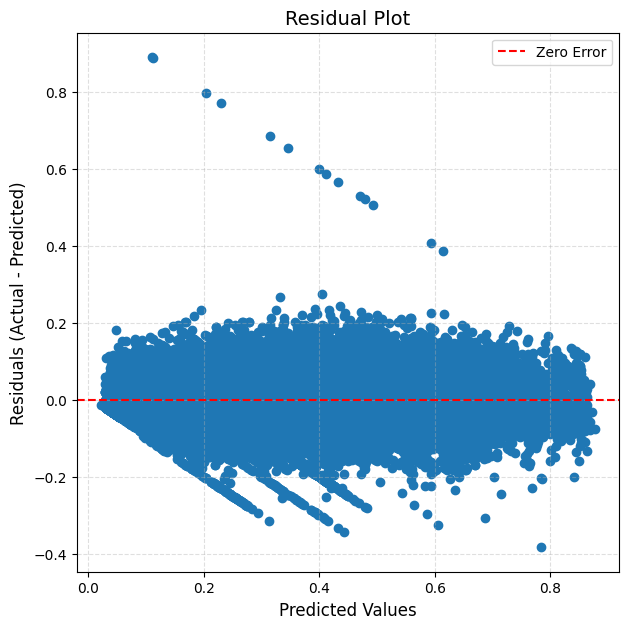

In [21]:
import matplotlib.pyplot as plt

residuals = y_val - y_pred

plt.figure(figsize=(7,7))
plt.scatter(y_pred, residuals)

plt.xlabel("Predicted Values", fontsize=12)
plt.ylabel("Residuals (Actual - Predicted)", fontsize=12)
plt.title("Residual Plot", fontsize=14)

plt.axhline(0, color='red', linestyle='--', label="Zero Error")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

In [24]:
feature_names

array(['num__num_lanes', 'num__curvature', 'num__speed_limit',
       'num__num_reported_accidents', 'cat__road_type_rural',
       'cat__road_type_urban', 'cat__lighting_dim', 'cat__lighting_night',
       'cat__weather_foggy', 'cat__weather_rainy',
       'cat__time_of_day_evening', 'cat__time_of_day_morning',
       'cat__road_signs_present_True', 'cat__public_road_True',
       'cat__holiday_True', 'cat__school_season_True'], dtype=object)

<Figure size 1000x600 with 0 Axes>

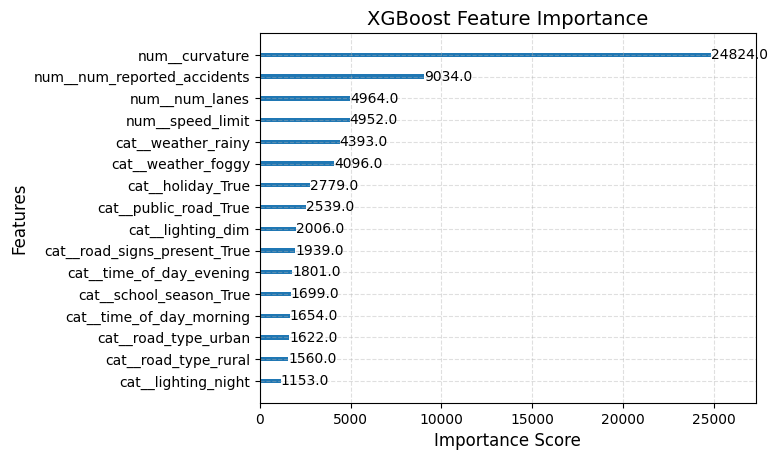

In [25]:
import matplotlib.pyplot as plt
from xgboost import plot_importance
feature_names = list(feature_names)
final_model.get_booster().feature_names = feature_names


plt.figure(figsize=(10, 6))
plot_importance(final_model, max_num_features=20)

plt.title("XGBoost Feature Importance", fontsize=14)
plt.xlabel("Importance Score", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.grid(linestyle="--", alpha=0.4)

plt.show()

### 1.6.2 DNN

In [15]:
import optuna
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import mean_squared_error

def objective(trial):
    n_layers = trial.suggest_int("n_layers", 2, 10)
    learning_rate = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
    dropout_rate = trial.suggest_float("dropout", 0.0, 0.5)

    model = tf.keras.Sequential()
    model.add(tf.keras.Input(shape=(X_train.shape[1],)))

    for i in range(n_layers):
        num_neurons = trial.suggest_int(f"n_units_l{i}", 8, 256)
        model.add(layers.Dense(num_neurons, activation='relu'))
        model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(1))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=[tf.keras.metrics.RootMeanSquaredError()]
    )

    callbacks = [
        EarlyStopping(patience=5, restore_best_weights=True)
    ]

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        batch_size=2048,
        epochs=50,
        verbose=0,
        callbacks=callbacks
    )

    rmse = history.history['val_root_mean_squared_error'][-1]
    return rmse

/home/rjain/projects/ml/DSAndAIBatch2025/tf_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-11-18 07:45:25.543114: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-11-18 07:45:25.668632: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-11-18 07:45:28.225310: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You ma

In [16]:
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=40)

print("Best params:", study.best_params)
print("Best value:", study.best_value)

[I 2025-11-18 07:45:34,312] A new study created in memory with name: no-name-d21dadfe-1d8a-4401-ade9-0dbc02f3e30f
I0000 00:00:1763451935.173269   39744 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5564 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070 Ti Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6
2025-11-18 07:45:39.527259: I external/local_xla/xla/service/service.cc:163] XLA service 0x76fe6801ea80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2025-11-18 07:45:39.527321: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 3070 Ti Laptop GPU, Compute Capability 8.6
2025-11-18 07:45:39.603608: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-11-18 07:45:40.095741: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] L

Best params: {'n_layers': 2, 'lr': 0.0021486905614530325, 'dropout': 0.03371369931792215, 'n_units_l0': 243, 'n_units_l1': 167}
Best value: 0.05712924897670746


In [20]:
from sklearn.metrics import mean_squared_error
import tensorflow as tf
from tensorflow.keras import layers, regularizers

model = tf.keras.Sequential()
model.add(tf.keras.Input(shape=(X_train.shape[1],)))
model.add(layers.Dense(243, activation='relu'))
model.add(layers.Dropout(0.03371369931792215))
model.add(layers.Dense(167, activation='relu'))
model.add(layers.Dropout(0.03371369931792215))
model.add(layers.Dense(1))

optimizer = tf.keras.optimizers.Adam(learning_rate=0.0021486905614530325)
model.compile(
    optimizer=optimizer,
    loss='mse',
    metrics=[tf.keras.metrics.RootMeanSquaredError()]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, verbose=1)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=512,
    callbacks=callbacks,
    verbose=1
)

y_pred_dnn = model.predict(X_val).flatten()

rmse_dnn = np.sqrt(mean_squared_error(y_val, y_pred_dnn))
print(f"Root Mean Squared Error: {rmse_dnn}")

score = r2_score(y_val, y_pred_dnn)
print("R2 score:", score)

Epoch 1/200
809/809 ━━━━━━━━━━━━━━━━━━━━ 27s 25ms/step - loss: 0.0056 - root_mean_squared_error: 0.0746 - val_loss: 0.0036 - val_root_mean_squared_error: 0.0598 - learning_rate: 0.0021
Epoch 2/200
809/809 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0037 - root_mean_squared_error: 0.0610 - val_loss: 0.0035 - val_root_mean_squared_error: 0.0590 - learning_rate: 0.0021
Epoch 3/200
809/809 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 0.0035 - root_mean_squared_error: 0.0594 - val_loss: 0.0034 - val_root_mean_squared_error: 0.0579 - learning_rate: 0.0021
Epoch 4/200
809/809 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 0.0035 - root_mean_squared_error: 0.0588 - val_loss: 0.0034 - val_root_mean_squared_error: 0.0582 - learning_rate: 0.0021
Epoch 5/200
809/809 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 0.0034 - root_mean_squared_error: 0.0582 - val_loss: 0.0033 - val_root_mean_squared_error: 0.0573 - learning_rate: 0.0021
Epoch 6/200
809/809 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0034 - root_m

In [19]:
score = r2_score(y_val, y_pred_dnn)
print("R2 score:", score)

R2 score: 0.8830022048614519
